# 01 — Logical qubits idle most of the time in sequential applications

Resource estimates for fault-tolerant algorithms spend much of
their qubit budget on qubits that wait. Large estimates already treat idle storage as
its own problem, with denser codes for qubits at rest (Gidney 2025, arXiv 2505.15917;
yoked surface codes, arXiv 2312.04522). Here: how much do logical qubits idle in compiled
circuits, and in what stretches?

**Source:** `python -m qec_timing.studies.idle` → `results/idle/idle.json` (pytket compile
to Clifford+T, ASAP schedule; `qec_timing.apps`). Labels: *measured* = computed here;
*interp.* = reading.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from qec_timing import plotting as P
P.style()
R = Path("..") / "results"

In [2]:
idle = json.loads((R / "idle" / "idle.json").read_text())
print(f"{'app':<12}{'model':<9}{'qubits':>7}{'idle':>7}{'>=10 steps':>12}{'>=40 rounds (d=5)':>19}{'longest':>9}")
for r in idle["rows"]:
    print(f"{r['app']:<12}{r['time_model']:<9}{r['qubits']:>7}{r['idle_fraction']:>7.0%}"
          f"{r['share_in_stretches_ge_steps']['10']:>12.0%}{r['share_in_stretches_ge_rounds']:>19.0%}"
          f"{r['longest_stretch_steps']:>9.0f}")

app         model     qubits   idle  >=10 steps  >=40 rounds (d=5)  longest
QFT-16      uniform       16    41%         68%                70%       56
QFT-16      magic         16    51%         54%                56%       29
Ising-16x8  uniform       16    14%          0%                 0%        3
Ising-16x8  magic         16    35%          0%                 0%        2
Adder-8     uniform       18    84%         93%                93%      171
Adder-8     magic         18    87%         93%                95%       59


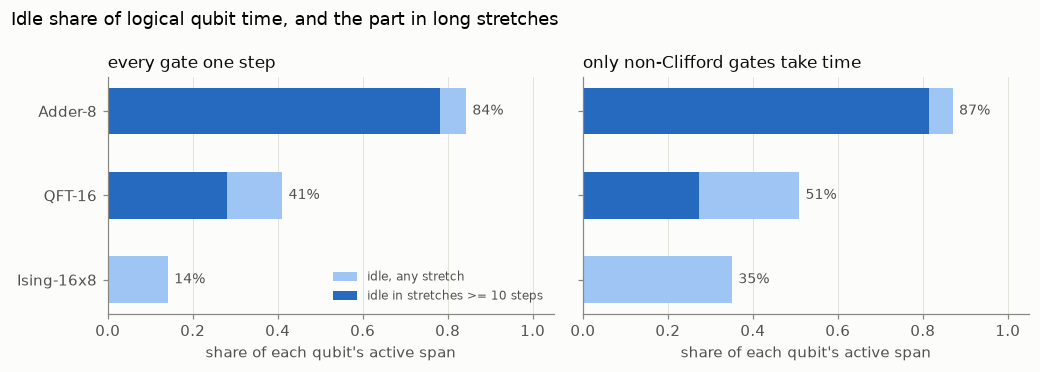

In [3]:
apps = ["Ising-16x8", "QFT-16", "Adder-8"]
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4), sharey=True)
for ax, tm, title in zip(axes, ("uniform", "magic"), ("every gate one step", "only non-Clifford gates take time")):
    rows = {r["app"]: r for r in idle["rows"] if r["time_model"] == tm}
    y = np.arange(len(apps))
    idle_frac = [rows[a]["idle_fraction"] for a in apps]
    long = [rows[a]["idle_fraction"] * rows[a]["share_in_stretches_ge_steps"]["10"] for a in apps]
    ax.barh(y, idle_frac, color=P.SEQUENTIAL[1], height=0.55, label="idle, any stretch")
    ax.barh(y, long, color=P.SEQUENTIAL[4], height=0.55, label="idle in stretches >= 10 steps")
    for yi, v in zip(y, idle_frac):
        ax.text(v + 0.015, yi, f"{v:.0%}", va="center", color=P.INK_2, fontsize=9)
    ax.set_yticks(y, apps); ax.set_xlim(0, 1.05); ax.set_xlabel("share of each qubit's active span")
    ax.set_title(title, loc="left"); ax.grid(axis="y", visible=False)
axes[0].legend(loc="lower right", fontsize=8)
fig.suptitle("Idle share of logical qubit time, and the part in long stretches", x=0.01, ha="left")
fig.tight_layout()
P.save(fig, "01_idle_in_applications_1")

**Reading.**
- *Measured:* sequential workloads leave most logical qubit time idle: the ripple-carry
  adder 84–87%, the QFT 41–51%. Most of it comes in long stretches: 93% of the adder's idle
  time is in stretches of at least 10 logical steps.
- *Measured:* a local, uniform workload (the Ising Trotter step) idles only in 1–3 step
  gaps: nothing for an interval choice to act on. That is the honest boundary of the claim.
- *Interp.:* at d = 5 and d rounds per logical step, 56–95% of the QFT's and adder's idle
  time sits in stretches of 40 rounds or more, longer than any dt* found for H2 (notebook
  08). In those stretches the qubit is a memory, and logical error per unit time — the
  quantity the interval optimises — is what counts.
- *Limits:* 16–18 logical qubits; no routing, factories or rotation synthesis, all of which
  lengthen waiting, so these fractions are lower bounds.